### Análise de Dados e treinamento de modelo de aprendizado de máquina

#### 1. Preparação inicial

In [1]:
# Importando bibliotecas para análise e processamento de dados
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Importando bibliotecas para aplicação de aprendizado de máquina
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Importando bibliotecas para salvar o modelo
import joblib

In [2]:
# Setando o caminho para o dataset
CAMINHO = '../data/processed/phishing-dataset-merged.csv'

# Carregando dataset
df = pd.read_csv(CAMINHO, keep_default_na=False)

#### 2. Análise exploratória

##### 2.1. Informações sobre a base de dados

In [3]:
# Visualizando as primeiras linhas do dataset
df.head()

,subject,body,fonte,is_malicious,num_urls,urls,subject_vazio,tipo
0,re : tenaska iv,"ok , since we don ' t appear to be able to hoo...",enron,0,0.0,0,0,legitimo
1,good day,from the desk of philip moore dept credit cont...,enron,1,0.0,0,0,spam
2,[use perl] headlines for -09-24,use perl daily headline mailer this week on pe...,spamAssasin,0,3.0,1,0,legitimo
3,we can do this,"dear sir, i am dr kabo hammed i have urgent an...",nigerian,1,0.0,0,0,phishing
4,outsourcing communication,access . benefits . benefits customer service ...,enron,0,1.0,1,0,legitimo


| Variável                           | Significado                   |
| ---------------------------------- |------------------------------ |
| `subject`       | Assunto do qual o e-mail foi nomeado.                 |
| `body`          | Mensagem, corpo do e-mail.                            |
| `fonte`         | Indica o dataset orignário daquela instância.         |
| `is_malicious`  | Variável alvo, indica se o e-mail é malicioso         |
| `num_urls`      | Indica número de _urls_ no e-mail.                    |
| `urls`          | Indica se há algum _url_ no e-mail.                   |
| `subject_vazio` | Indica se o *subject* daquele e-mail era vazio ou não antes do processamento inicial.|
| `tipo`          | Indica se e-mail malicioso é *spam* ou *phishing*     |


In [4]:
# Visualizando formato do dataset
df.shape

(36498, 8)

In [5]:
# Informações gerais dos dados
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36498 entries, 0 to 36497
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subject        36498 non-null  str    
 1   body           36498 non-null  str    
 2   fonte          36498 non-null  str    
 3   is_malicious   36498 non-null  int64  
 4   num_urls       36498 non-null  float64
 5   urls           36498 non-null  int64  
 6   subject_vazio  36498 non-null  int64  
 7   tipo           36498 non-null  str    
dtypes: float64(1), int64(3), str(4)
memory usage: 2.2 MB


In [6]:
# Validação de valores nulos
soma_nulos = df.isnull().sum()
print(f'Valores nulos por coluna: \n{soma_nulos}')

Valores nulos por coluna: 
subject          0
body             0
fonte            0
is_malicious     0
num_urls         0
urls             0
subject_vazio    0
tipo             0
dtype: int64


In [7]:
# Acrescentando tamanho de textos de body e numeros de caracteres, para análise
df['num_caracteres'] = df['body'].fillna('').apply(len)
df['num_palavras'] = df['body'].fillna('').apply(lambda x: len(x.split()))

In [8]:
# Estatatísticas descritivas dasa variáveis numéricas
df.describe(include=['int64', 'float64'])

,is_malicious,num_urls,urls,subject_vazio,num_caracteres,num_palavras
count,36498.000000,36498.000000,36498.000000,36498.000000,36498.000000,36498.000000
mean,0.500630,1.296263,0.303880,0.006795,1663.329169,310.599704
std,0.500006,25.383302,0.459938,0.082152,5592.714040,915.113816
min,0.000000,0.000000,0.000000,0.000000,11.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,375.000000,75.000000
50%,1.000000,0.000000,0.000000,0.000000,823.000000,162.000000
75%,1.000000,1.000000,1.000000,0.000000,1862.000000,358.000000
max,1.000000,4637.000000,1.000000,1.000000,552289.000000,91531.000000


In [9]:
# Estatísticas descritivas das variáveis categóricas
df.describe(include=['str'])

,subject,body,fonte,tipo
count,36498,36498,36498,36498
unique,28560,36498,4,3
top,,"ok , since we don ' t appear to be able to hoo...",enron,legitimo
freq,252,1,27165,18226


##### 2.2 Geração de gráficos para visualização

In [10]:
# Cores utilizadas para plotagem
COR_PRIMARIA  = '#2a78d6'    # Principalmente para legitimo
COR_SECUNDARIA = '#eb6834'   # Principalmente para malicioso
COR_TERCIARIA  = '#1baf7a'   # Em casos necessários

Número absoluto da variável alvo: 
is_malicious
1    18272
0    18226
Name: count, dtype: int64
Percentual da variável alvo: 
is_malicious
1    50.063017
0    49.936983
Name: proportion, dtype: float64


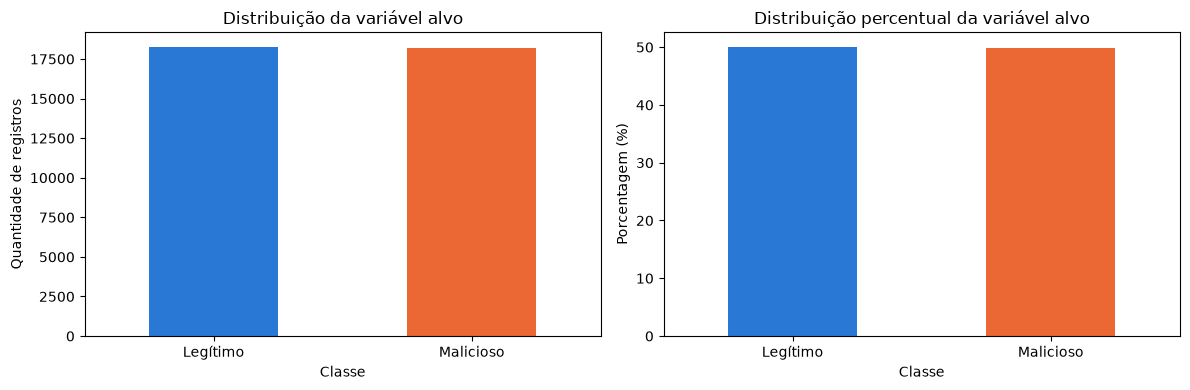

In [11]:
# Distribuição da variável alvo
contagem = df['is_malicious'].value_counts()
percentual = df['is_malicious'].value_counts(normalize = True) * 100

print(f'Número absoluto da variável alvo: \n{contagem}')
print(f'Percentual da variável alvo: \n{percentual}')

# Figuras
fig, axes = plt.subplots(1, 2, figsize = (12, 4))

# Gráfico 1 - quantidade
contagem.plot(kind = "bar", ax = axes[0], color= [COR_PRIMARIA, COR_SECUNDARIA])
axes[0].set_title("Distribuição da variável alvo")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Quantidade de registros")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Legítimo", "Malicioso"], rotation = 0)

# Gráfico 2 - percentual
percentual.plot(kind = "bar", ax = axes[1], color= [COR_PRIMARIA, COR_SECUNDARIA])
axes[1].set_title("Distribuição percentual da variável alvo")
axes[1].set_xlabel("Classe")
axes[1].set_ylabel("Porcentagem (%)")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Legítimo", "Malicioso"], rotation=0)

plt.tight_layout()
plt.show()

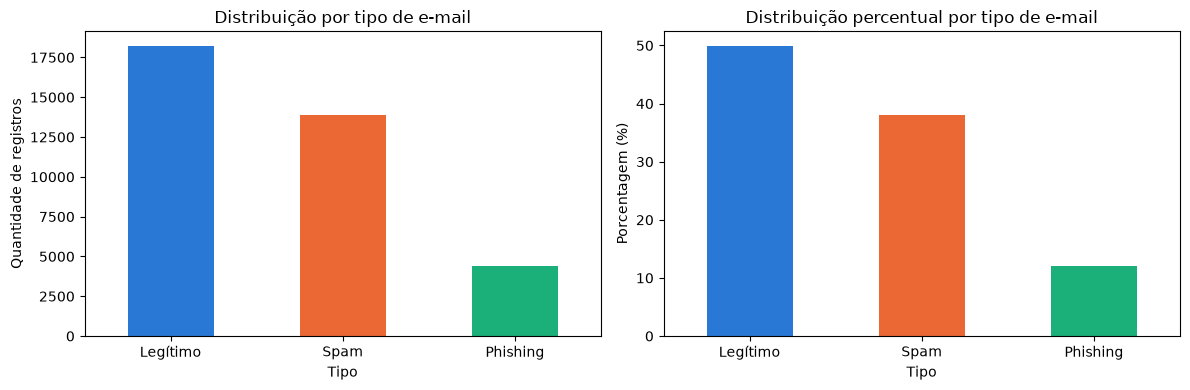

In [12]:
contagem_por_tipo = df['tipo'].value_counts().reindex(['legitimo', 'spam', 'phishing'])
percentual_por_tipo = (df['tipo'].value_counts(normalize = True) * 100).reindex(['legitimo', 'spam', 'phishing'])

# Figuras
fig, axes = plt.subplots(1, 2, figsize = (12, 4))

# Gráfico 1 - quantidade
contagem_por_tipo.plot(kind='bar', ax=axes[0], color=[COR_PRIMARIA, COR_SECUNDARIA, COR_TERCIARIA])
axes[0].set_title('Distribuição por tipo de e-mail')
axes[0].set_xlabel('Tipo')
axes[0].set_ylabel('Quantidade de registros')
axes[0].set_xticklabels(['Legítimo', 'Spam', 'Phishing'], rotation=0)

# Gráfico 2 - percentual
percentual_por_tipo.plot(kind='bar', ax=axes[1], color=[COR_PRIMARIA, COR_SECUNDARIA, COR_TERCIARIA])
axes[1].set_title('Distribuição percentual por tipo de e-mail')
axes[1].set_xlabel('Tipo')
axes[1].set_ylabel('Porcentagem (%)')
axes[1].set_xticklabels(['Legítimo', 'Spam', 'Phishing'], rotation=0)

plt.tight_layout()
plt.show()

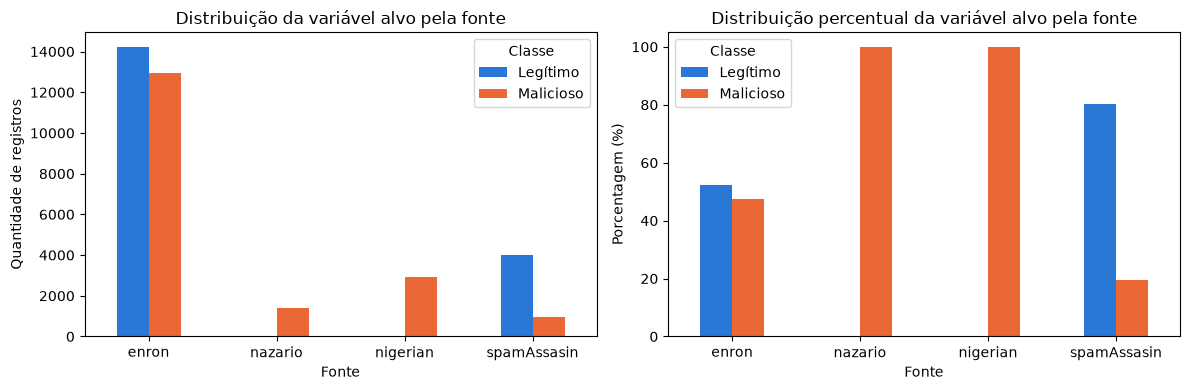

In [13]:
# Distribuição de classes da variável alvo pela fonte
contagem_por_classes = df.groupby('fonte')['is_malicious'].value_counts().unstack()
percentual_por_classes = (df.groupby('fonte')['is_malicious'].value_counts(normalize = True) * 100).unstack()

# Figuras
fig, axes = plt.subplots(1, 2, figsize = (12, 4))

# Gráfico 1 - quantidade
contagem_por_classes.plot(kind = "bar", ax = axes[0], color = [COR_PRIMARIA, COR_SECUNDARIA])
axes[0].set_title("Distribuição da variável alvo pela fonte")
axes[0].set_xlabel("Fonte")
axes[0].set_ylabel("Quantidade de registros")
axes[0].tick_params(axis="x", rotation=0)
axes[0].set_xticks(range(len(contagem_por_classes)))
axes[0].legend(["Legítimo", "Malicioso"], title = 'Classe')

# Gráfico 2 - percentual
percentual_por_classes.plot(kind = "bar", ax = axes[1], color = [COR_PRIMARIA, COR_SECUNDARIA])
axes[1].set_title("Distribuição percentual da variável alvo pela fonte")
axes[1].set_xlabel("Fonte")
axes[1].set_ylabel("Porcentagem (%)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].set_xticks(range(len(percentual_por_classes)))
axes[1].legend(["Legítimo", "Malicioso"], title = 'Classe')


plt.tight_layout()
plt.show()

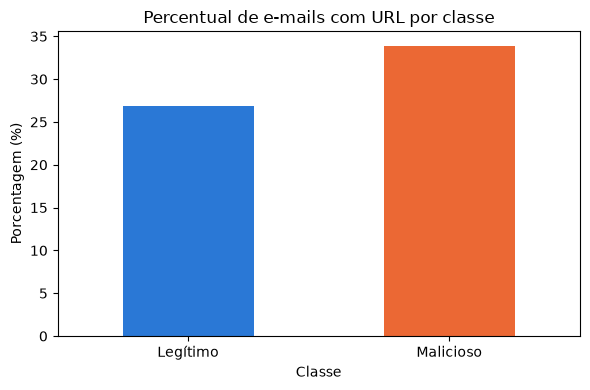

In [14]:
# percentual_urls de e-mails com URL, por classe
percentual_urls = df.groupby('is_malicious')['urls'].mean() * 100

fig, axes = plt.subplots(figsize=(6, 4))
percentual_urls.plot(kind='bar', ax=axes, color=[COR_PRIMARIA, COR_SECUNDARIA])
axes.set_title('Percentual de e-mails com URL por classe')
axes.set_xlabel('Classe')
axes.set_ylabel('Porcentagem (%)')
axes.set_xticks([0, 1])
axes.set_xticklabels(['Legítimo', 'Malicioso'], rotation=0)

plt.tight_layout()
plt.show()

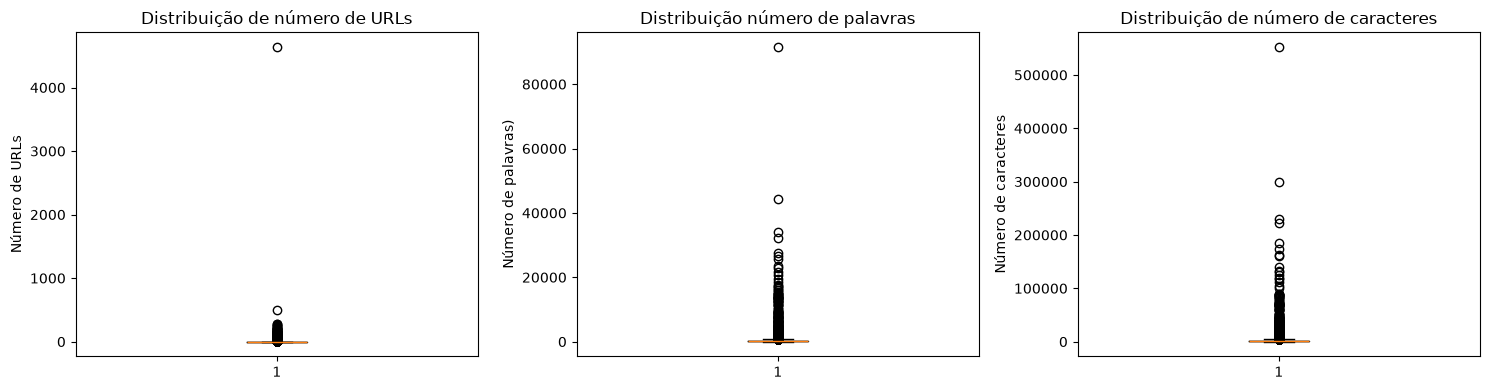

In [15]:
# Distribuição de num_urls

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].boxplot(df['num_urls'])
axes[0].set_title('Distribuição de número de URLs')
axes[0].set_ylabel('Número de URLs')

axes[1].boxplot(df['num_palavras'])
axes[1].set_title('Distribuição número de palavras')
axes[1].set_ylabel('Número de palavras)')

axes[2].boxplot(df['num_caracteres'])
axes[2].set_title('Distribuição de número de caracteres')
axes[2].set_ylabel('Número de caracteres')

plt.tight_layout()
plt.show()

Pode-se verificar que as três variáveis: *num_urls*, *num_palavras* e *num_caracteres* possuem *outliers* extremos, mesmo após a remoção de registros corrompidos no processamento inicial da base. Esses valores serão tratados na seção 3.

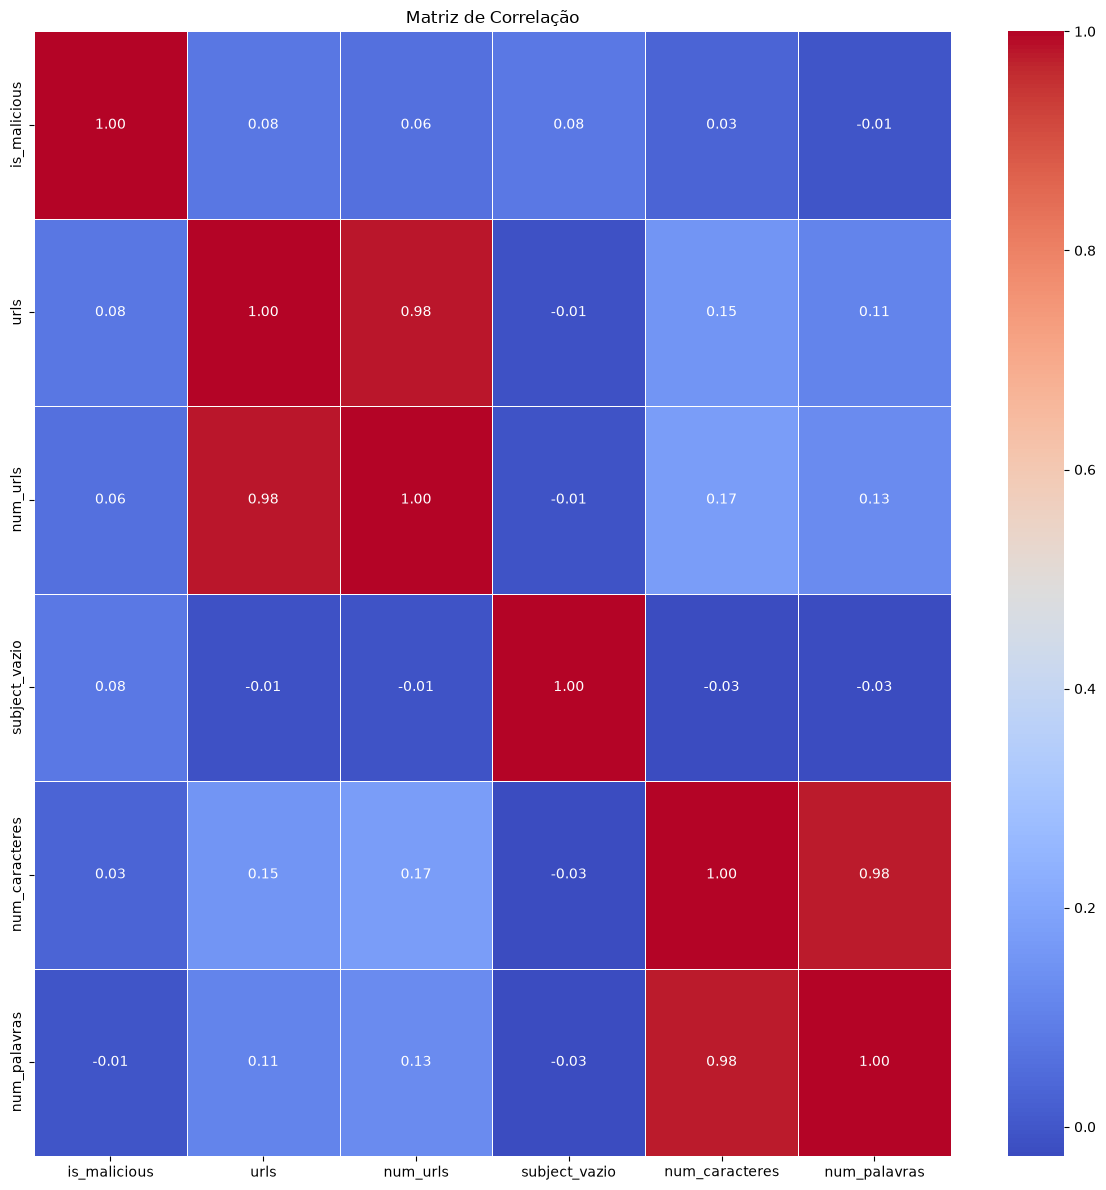

In [16]:
col_correlacao = ['is_malicious', 'urls', 'num_urls', 'subject_vazio', 'num_caracteres', 'num_palavras']

# Matriz de correlação
corr = df[col_correlacao].corr(method='spearman')

# Geração do heatmap
plt.figure(figsize=(12, 12))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlação')

plt.tight_layout()
plt.show()

Podemos verificar a ausência de correlação forte entre as variáveis numéricas e a variável alvo, isso provavelmente se deve ao fato de que o sinal discriminativo está concentrado no texto de *subject* e *body*, não capturado nessa matriz.

Também foram observadas correlações fortes entre *urls* e *num_urls*, e entre *num_caracteres* e *num_palavras* o que era esperado, já que cada par é derivado da mesma lógica.

#### 3. Pré-processamento

##### 3.1 Tratamento de valores extremos residuais

Os valores extremos remanescentes, e-mails muito longos ou com muitas urls observados nos *boxplots*, correspondem a conteúdo real, como um *phishing* com uma lista extensa de destinatários, ou um digest de blog com centenas de links, e não a erros de extração. Por isso, as linhas foram mantidas, e o efeito dos valores extremos foi contido de duas formas: transformação logarítmica nas variáveis numéricas de contagem, e um limite de tamanho para o texto usado na vetorização.

In [17]:
# Transformação log1p para reduzir a influência de valores extremos, preservando o registro
df['log_num_urls'] = np.log1p(df['num_urls'])
df['log_num_caracteres'] = np.log1p(df['num_caracteres'])
df['log_num_palavras'] = np.log1p(df['num_palavras'])

# Comparação das novas variáveis
df[['num_urls', 'log_num_urls', 'num_caracteres', 'log_num_caracteres', 'num_palavras', 'log_num_palavras']].describe()

,num_urls,log_num_urls,num_caracteres,log_num_caracteres,num_palavras,log_num_palavras
count,36498.000000,36498.000000,36498.000000,36498.000000,36498.000000,36498.000000
mean,1.296263,0.368461,1663.329169,6.693038,310.599704,5.066014
std,25.383302,0.646583,5592.714040,1.168606,915.113816,1.140533
min,0.000000,0.000000,11.000000,2.484907,1.000000,0.693147
25%,0.000000,0.000000,375.000000,5.929589,75.000000,4.330733
50%,0.000000,0.000000,823.000000,6.714171,162.000000,5.093750
75%,1.000000,0.693147,1862.000000,7.529943,358.000000,5.883322
max,4637.000000,8.442039,552289.000000,13.221829,91531.000000,11.424444


A partir da análise visual de extremos foram observados e-mails (aproximadamente 1,5% do total, concentrados na fonte SpamAssasin) cujo *body* preserva marcadores de estrutura MIME não decodificados na extração original dos dados, como *content-type* e *boundary*, em vez de conter apenas o texto legível do e-mail. Esses marcadores são ruído para a vetorização: não representam vocabulário relacionado a *phishing* ou *spam*, apenas artefatos do formato de transporte da mensagem.

Optou-se por não remover esses registros, pois removê-los introduziria viés de classe (a proporção de e-mails maliciosos entre eles é maior que a da base geral) e reduziria o tamanho útil do conjunto de dados. Também não se buscou decodificar o conteúdo MIME por completo, por estar fora do escopo desta análise.

A limpeza aplicada remove apenas os marcadores e seus valores imediatos, preservando o restante do texto ao redor de cada ocorrência. O resultado é salvo em uma coluna separada (*body_limpo*), sem sobrescrever o *body* original, para manter o texto bruto disponível para conferência.

In [18]:
# Limpeza leve de marcadores MIME
padrao_mime = r'content-type:\s*\S+(?:;\s*\S+)*|content-transfer-encoding:\s*\S+|mime-version:?\s*\S*|------=_\S*|boundary=\S*'
marcadores_iniciais = df['body'].str.contains(padrao_mime, regex=True, case=False).sum()
print(f'Marcadores MIME antes da limpeza: {marcadores_iniciais}')

# Criando nova coluna a partir da limpeza de body
df['body_limpo'] = df['body'].str.replace(padrao_mime, '', regex=True)

# Verificando a existência de marcadores MIME após a limpeza
marcadores_restantes = df['body_limpo'].str.contains(padrao_mime, regex=True, case=False).sum()
print(f'Marcadores MIME restantes após limpeza: {marcadores_restantes}')

Marcadores MIME antes da limpeza: 522
Marcadores MIME restantes após limpeza: 0


In [19]:
# Limite de caracteres usado apenas no momento de vetorizar o texto, para um documento longo não dominar as estatísticas
limite_caracteres = 20000
df['body_vetorizacao'] = df['body_limpo'].str.slice(0, limite_caracteres)

##### 3.2 Preparando os dados

In [20]:
# Texto final usado nos testes de validação e na vetorização
df['texto'] = df['subject'] + ' ' + df['body_vetorizacao']

In [21]:
# Pré-processamento de variáveis numéricas
num_transformador = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Pré-processamento de variáveis textuais
txt_transformador = Pipeline(steps=[
    ('vetor', TfidfVectorizer(max_features=50000, sublinear_tf=True))
])

# Montando pipeline
pre_processador = ColumnTransformer(
    transformers = [
        ('numerico', num_transformador, ['log_num_urls', 'log_num_palavras']),
        ('texto', txt_transformador, 'texto')
    ])

##### 3.3 Verificando vazamento entre as fontes

In [22]:
# Função para calcular métricas
def calcula_metricas(y_teste, y_pred, tag=None, fim=0):
    if tag != None:
        print(tag)
    print(f'Acurácia: {accuracy_score(y_teste, y_pred)}')
    print(f'F1-Score: {f1_score(y_teste, y_pred)}')
    print(f'Recall: {recall_score(y_teste, y_pred)}')
    print(f'Precision: {precision_score(y_teste, y_pred)}')
    if not fim:
        print('\n')

In [23]:
# Split aleatório
X = df[['texto', 'log_num_urls', 'log_num_palavras']]
y = df['is_malicious']

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.1, stratify=y, random_state=2026)

X_treino_processado = pre_processador.fit_transform(X_treino)
X_teste_processado = pre_processador.transform(X_teste)

modelo_reg_log = LogisticRegression(max_iter=1000).fit(X_treino_processado, y_treino)
y_pred = modelo_reg_log.predict(X_teste_processado)

calcula_metricas(y_teste, y_pred)

# Treina sem Nigerian e testa Nigerian
X = df[['texto', 'log_num_urls', 'log_num_palavras', 'fonte']]
y = df[['is_malicious', 'fonte']]

X_treino = X[X['fonte'] == 'enron'].drop(columns='fonte')
X_teste = X[X['fonte'] == 'spamAssasin'].drop(columns='fonte')

y_treino = y[y['fonte'] == 'enron']['is_malicious'].to_numpy()
y_teste = y[y['fonte'] == 'spamAssasin']['is_malicious'].to_numpy()

X_treino_processado = pre_processador.fit_transform(X_treino)
X_teste_processado = pre_processador.transform(X_teste)

modelo_reg_log = LogisticRegression(max_iter=1000).fit(X_treino_processado, y_treino)
y_pred = modelo_reg_log.predict(X_teste_processado)

calcula_metricas(y_teste, y_pred)

# Treina sem o Nazario e testa Nazario
X_treino = X[X['fonte'] != 'nazario'].drop(columns='fonte')
X_teste = X[X['fonte'] == 'nazario'].drop(columns='fonte')

y_treino = y[y['fonte'] != 'nazario']['is_malicious'].to_numpy()
y_teste = y[y['fonte'] == 'nazario']['is_malicious'].to_numpy()

X_treino_processado = pre_processador.fit_transform(X_treino)
X_teste_processado = pre_processador.transform(X_teste)

modelo_reg_log = LogisticRegression(max_iter=1000).fit(X_treino_processado, y_treino)
y_pred = modelo_reg_log.predict(X_teste_processado)

calcula_metricas(y_teste, y_pred, fim=1)

Acurácia: 0.9789041095890411
F1-Score: 0.9789674952198852
Recall: 0.9808429118773946
Precision: 0.9770992366412213


Acurácia: 0.4553877139979859
F1-Score: 0.4154777345438824
Recall: 0.9886831275720165
Precision: 0.26299945265462504


Acurácia: 0.836376404494382
F1-Score: 0.9108986615678776
Recall: 0.836376404494382
Precision: 1.0


Na versão inicial da base, o split aleatório resultou em 98,2% de acurácia, mas esse valor não reflete a capacidade real de generalização do modelo: treinando no Enron e testando no SpamAssassin, a acurácia caiu para 36%, o que evidencia que boa parte do desempenho vem de padrões específicos de cada fonte, e não de sinal genuíno de spam ou phishing. Já um modelo treinado sem o Nazario recuperou 85,3% dos e-mails de phishing dessa fonte.

Para reduzir esse vazamento, foram adotadas duas medidas: a inclusão da base Nigerian Fraud, que elevou os e-mails de phishing de cerca de 1.400 para 4.300, e a remoção de artefatos que identificam a coleta de cada corpus, como endereços de e-mail, anos, nomes de organizações e de listas de discussão, rótulos vazados no texto e marcadores de codificação.

Após essas medidas, o split aleatório resultou em 98,0% de acurácia, o recall sem o Nigerian foi de 99,0% e o recall sem o Nazario foi de 83,6%. A redução em relação aos valores iniciais é esperada, pois o modelo deixou de contar com atalhos que não indicam fraude, e o resultado passa a refletir melhor a generalização real. O valor alto no teste sem o Nigerian deve ser interpretado com cautela, já que o Enron e o SpamAssassin contêm golpes do mesmo tipo rotulados como spam. Além disso, o phishing de credenciais ainda provém de uma única fonte (Nazario), e o vocabulário específico de cada corpus não pôde ser removido por completo. Isso constitui uma limitação do projeto quanto às bases disponíveis.

A divisão treino/teste do modelo final será estratificada por classe e fonte, complementada por uma validação entre fontes para uma avaliação mais confiável.

#### 4. Analise de modelos

In [24]:
# Chave combianada, pois garante representatividade de classe e fonte no split
df['chave_estratificacao'] = df['is_malicious'].astype(str) + '_' + df['fonte']

# Divisão do dataset para treinamento
X = df[['texto', 'log_num_urls', 'log_num_palavras']]
y = df['is_malicious']

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.1, stratify=df['chave_estratificacao'], random_state=2026)

X_treino_processado = pre_processador.fit_transform(X_treino)
X_teste_processado = pre_processador.transform(X_teste)

# Analisando modelo regressão logística
modelo_reg_log = LogisticRegression(max_iter=1000, class_weight='balanced')
modelo_reg_log.fit(X_treino_processado, y_treino)
y_pred_reg = modelo_reg_log.predict(X_teste_processado)

calcula_metricas(y_teste, y_pred_reg, 'Regressão Logística')

# Analisando modelo árvore de decisão
modelo_dt = tree.DecisionTreeClassifier()
modelo_dt = modelo_dt.fit(X_treino_processado, y_treino)
y_pred_av = modelo_dt.predict(X_teste_processado)

calcula_metricas(y_teste, y_pred_av, 'Árvore de Decisão')

# Analisando modelo support vector machines
modelo_svm = LinearSVC(dual=False, class_weight='balanced')
modelo_svm = modelo_svm.fit(X_treino_processado, y_treino)
y_pred_svm = modelo_svm.predict(X_teste_processado)

calcula_metricas(y_teste, y_pred_svm, 'SVM', fim=1)

Regressão Logística
Acurácia: 0.98
F1-Score: 0.9801252382248843
Recall: 0.9846827133479212
Precision: 0.975609756097561


Árvore de Decisão
Acurácia: 0.9186301369863014
F1-Score: 0.9192276312211042
Recall: 0.9245076586433261
Precision: 0.914007571660357


SVM
Acurácia: 0.9865753424657534
F1-Score: 0.9866083629406942
Recall: 0.987417943107221
Precision: 0.985800109229929


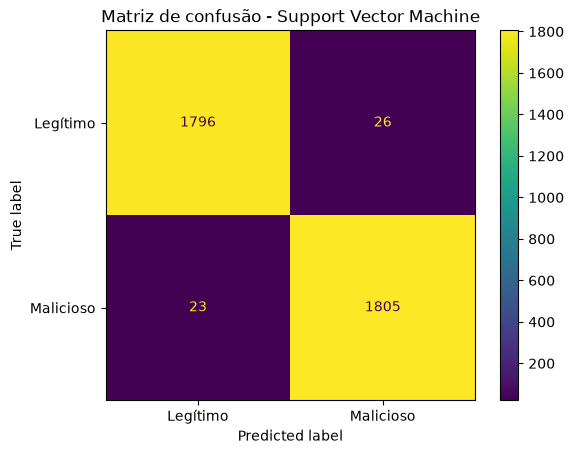

In [25]:
# Fazendo plot da matriz de confusão do modelo com melhor desempenho 
ConfusionMatrixDisplay(
    confusion_matrix= confusion_matrix(y_teste, y_pred_svm),
    display_labels=["Legítimo", "Malicioso"]
).plot()

plt.title(f"Matriz de confusão - {'Support Vector Machine'}")
plt.show()

In [26]:
# Nomes das features, na mesma ordem usada pelo pre_processador
nomes_features = pre_processador.get_feature_names_out()

# Pesos prendidos pela support vector machine
pesos = modelo_svm.coef_[0]

# Junta nome e peso, ordenado do mais do mais relacionado a legitimo para o mais malicioso
ranking = pd.Series(pesos, index=nomes_features).sort_values()

# Printando o ranking
print('10 palavras mais associadas a legítimo')
print(ranking.head(10))

print('\n10 palabras mais associadas a malicioso')
print(ranking.tail(10))

10 palavras mais associadas a legítimo
texto__louise      -3.241745
texto__wrote       -3.004487
texto__713         -2.920199
texto__the         -2.717483
texto__fork        -2.534990
texto__employees   -2.447801
texto__url         -2.441662
texto__thanks      -2.317964
texto__daren       -2.209541
texto__attached    -2.051652
dtype: float64

10 palabras mais associadas a malicioso
texto__money        1.580705
texto__viagra       1.591768
texto__life         1.609618
texto__hello        1.623130
texto__kindly       1.659753
texto__sightings    2.048283
texto__account      2.061642
texto__remove       2.267925
texto__you          2.341559
texto__your         2.702467
dtype: float64


#### 5. Salvando modelo

In [27]:
modelo = LogisticRegression(class_weight='balanced')

pipeline = Pipeline([
    ('pre', pre_processador),
    ('clf', modelo),
])

pipeline.fit(X_treino, y_treino)

,steps,"[('pre', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerico', ...), ('texto', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [28]:
joblib.dump(pipeline, '../model/risk_model.joblib')
pd.Series(X_teste.index, name='id').to_csv('../data/processed/test_ids.csv', index=False)